# Issue #354 — strictly-prior low-N Top-2 selector data

This executed notebook profiles the outcome-separated 10h feature panel. 2017–2021 are expanding OOF rows; 2022–2024 are exposed transfer rows generated by a model frozen through 2021.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
repo = Path.cwd()
features = pd.read_parquet(repo / 'results/low_n_selector_data/features/selector_features.parquet')
labels = pd.read_parquet(repo / 'results/low_n_selector_data/labels/selector_labels.parquet')
coverage = pd.read_csv(repo / 'results/low_n_selector_data/analysis/coverage.csv')
parity = pd.read_csv(repo / 'results/low_n_selector_data/analysis/accepted_surface_parity.csv')
freeze = json.loads((repo / 'results/low_n_selector_data/FREEZE_RECEIPT.json').read_text())
len(features), len(labels), freeze['feature_frame_sha256']

(134822,
 134822,
 'b7407840129055457b491c93e1abf8f82b18025ad519fbac45f445dca4e11e1a')

## Coverage and completeness

In [2]:
coverage.assign(label_rate=lambda x: x.label_available / x.fixtures)

,issue_year,prediction_role,issues,fixtures,median_fixtures_per_issue,label_available,mean_books,mean_retained_mass,label_rate
0,2017,STRICTLY_PRIOR_EXPANDING_OOF,48,16859,444.0,16733,13.154576,0.740560,0.992526
1,2018,STRICTLY_PRIOR_EXPANDING_OOF,59,19222,456.0,19018,13.113568,0.741928,0.989387
2,2019,STRICTLY_PRIOR_EXPANDING_OOF,53,16222,412.0,16098,12.883183,0.741204,0.992356
3,2020,STRICTLY_PRIOR_EXPANDING_OOF,38,9633,363.0,9508,13.165058,0.740762,0.987024
4,2021,STRICTLY_PRIOR_EXPANDING_OOF,63,20969,456.0,20674,12.747866,0.738069,0.985932
5,2022,FROZEN_THROUGH_2021_TRANSFER,62,19152,446.0,18941,12.969350,0.738443,0.988983
6,2023,FROZEN_THROUGH_2021_TRANSFER,53,14675,385.0,14548,13.128722,0.741468,0.991346
7,2024,FROZEN_THROUGH_2021_TRANSFER,66,18090,386.0,17933,13.376949,0.743381,0.991321


In [3]:
missing = (features.isna().mean() * 100).sort_values(ascending=False).rename('missing_pct')
missing.to_frame().head(20)

,missing_pct
issue,0.0
issue_year,0.0
issue_anchor_ts,0.0
match_idx,0.0
prediction_role,0.0
train_year_max,0.0
baseline_support,0.0
omitted_outcome,0.0
retained_mass,0.0
p_min,0.0


## Top-2 calibration by year

In [4]:
panel = features.merge(labels[['issue','match_idx','label_available','top2_hit']], on=['issue','match_idx'], validate='one_to_one')
settled = panel[panel.label_available].copy()
settled['top2_hit_float'] = settled.top2_hit.astype(float)
annual = settled.groupby('issue_year').agg(issues=('issue','nunique'), fixtures=('match_idx','size'), mean_retained=('retained_mass','mean'), actual_top2=('top2_hit_float','mean'), mean_books=('n_available_books','mean')).reset_index()
annual['actual_minus_predicted'] = annual.actual_top2 - annual.mean_retained
annual

,issue_year,issues,fixtures,mean_retained,actual_top2,mean_books,actual_minus_predicted
0,2017,48,16733,0.740506,0.748760,13.157653,0.008253
1,2018,59,19018,0.741873,0.745189,13.118993,0.003315
2,2019,53,16098,0.741228,0.740465,12.892595,-0.000763
3,2020,38,9508,0.740592,0.745267,13.179638,0.004675
4,2021,63,20674,0.738023,0.741221,12.756264,0.003198
5,2022,62,18941,0.738404,0.736709,12.972018,-0.001696
6,2023,53,14548,0.741447,0.742714,13.136307,0.001267
7,2024,66,17933,0.743333,0.742486,13.382925,-0.000847


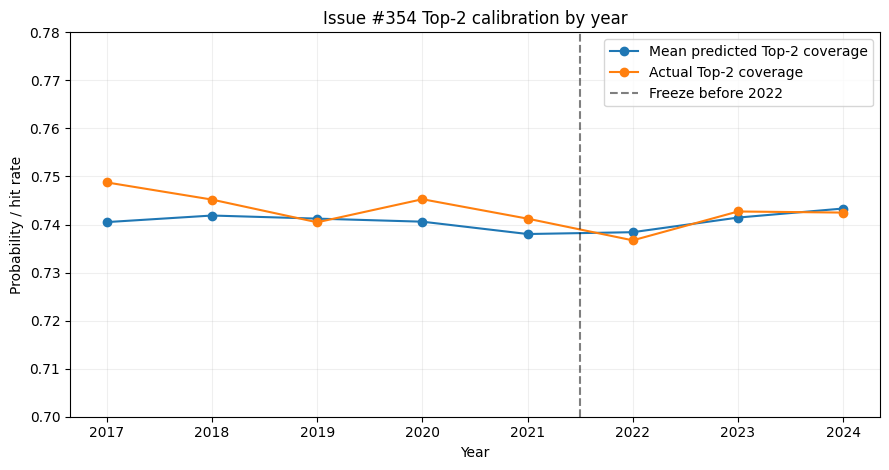

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(annual.issue_year, annual.mean_retained, marker='o', label='Mean predicted Top-2 coverage')
ax.plot(annual.issue_year, annual.actual_top2, marker='o', label='Actual Top-2 coverage')
ax.axvline(2021.5, color='black', linestyle='--', alpha=.5, label='Freeze before 2022')
ax.set(title='Issue #354 Top-2 calibration by year', xlabel='Year', ylabel='Probability / hit rate', ylim=(.70,.78))
ax.grid(alpha=.2); ax.legend(); fig.tight_layout()
fig.savefig(repo / 'docs/research/figures/issue_354_top2_calibration.png', dpi=160)
plt.show()

## Probability distribution and calibration bins

In [6]:
settled['retained_bin'] = pd.cut(settled.retained_mass, bins=np.linspace(.45,1,12), include_lowest=True)
calibration = settled.groupby(['issue_year','retained_bin'], observed=True).agg(fixtures=('match_idx','size'), predicted=('retained_mass','mean'), actual=('top2_hit_float','mean')).reset_index()
calibration['residual'] = calibration.actual - calibration.predicted
calibration.head(20)

,issue_year,retained_bin,fixtures,predicted,actual,residual
0,2017,"(0.65, 0.7]",1006,0.692744,0.705765,0.013022
1,2017,"(0.7, 0.75]",10507,0.727221,0.737794,0.010573
2,2017,"(0.75, 0.8]",4528,0.767315,0.769214,0.001899
3,2017,"(0.8, 0.85]",515,0.819264,0.850485,0.031221
4,2017,"(0.85, 0.9]",130,0.869504,0.800000,-0.069504
5,2017,"(0.9, 0.95]",38,0.920188,0.921053,0.000864
6,2017,"(0.95, 1.0]",9,0.973349,0.777778,-0.195571
7,2018,"(0.65, 0.7]",1079,0.691976,0.691381,-0.000595
8,2018,"(0.7, 0.75]",11689,0.727652,0.730088,0.002436
9,2018,"(0.75, 0.8]",5371,0.767746,0.776764,0.009018


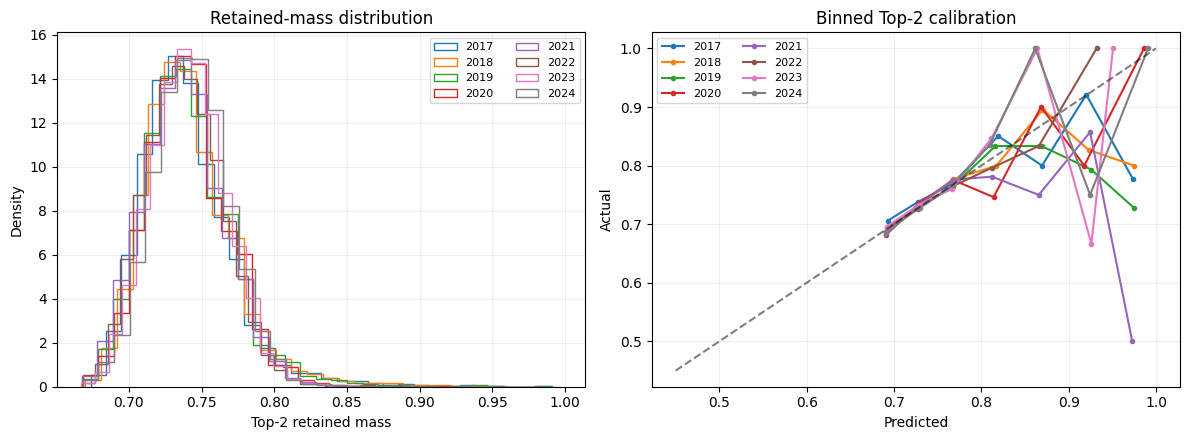

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for year, group in settled.groupby('issue_year'):
    axes[0].hist(group.retained_mass, bins=30, density=True, histtype='step', label=str(year))
for year, group in calibration.groupby('issue_year'):
    axes[1].plot(group.predicted, group.actual, marker='.', label=str(year))
axes[1].plot([.45,1],[.45,1], color='black', linestyle='--', alpha=.5)
axes[0].set(title='Retained-mass distribution', xlabel='Top-2 retained mass', ylabel='Density')
axes[1].set(title='Binned Top-2 calibration', xlabel='Predicted', ylabel='Actual')
axes[0].legend(ncol=2, fontsize=8); axes[1].legend(ncol=2, fontsize=8)
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(repo / 'docs/research/figures/issue_354_panel_profile.png', dpi=160)
plt.show()

## Source parity and temporal assertions

In [8]:
parity

,years,compared_cells,max_abs_delta_vs_candidate_diagnostic,exact_cells_vs_candidate_diagnostic,nonzero_cells,nonzero_max_abs_delta_vs_candidate_diagnostic,nonzero_exact_cells_vs_candidate_diagnostic,max_abs_delta_vs_accepted_q_eu_bjline,exact_cells_vs_accepted_q_eu_bjline,interpretation
0,2022-2024,155751,0.052628,62259,62259,0.0,62259,0.0,155751,same frozen architecture refit through 2021; n...


In [9]:
assert set(features.issue_year) == set(range(2017, 2025))
assert (features.train_year_max < features.issue_year).all()
assert set(features.loc[features.issue_year >= 2022, 'train_year_max']) == {2021}
assert not {'result_code','top2_hit','winning_sp','settlement_sp'} & set(features.columns)
assert features.isna().sum().sum() == 0
'All notebook assertions passed.'

'All notebook assertions passed.'

## Decision boundary

This notebook establishes data readiness only. It does not select S1–S3, inspect transfer-year performance to tune parameters, or authorize a betting candidate.